<a href="https://colab.research.google.com/github/charlie-cassidy1/portfolio-analysis/blob/main/portfolio_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install yfinance --quiet

import yfinance as yf

tickers = ["AAPL", "MSFT", "JPM", "KO", "SPY"]  # SPY tracks the S&P 500, the benchmark
prices = yf.download(tickers, start="2023-01-01", end="2026-11-01", auto_adjust=True)["Close"]

prices.tail()

/tmp/ipykernel_993/2853605243.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(tickers, start="2023-01-01", end="2026-11-01")["Close"]
[*********************100%***********************]  5 of 5 completed


Ticker,AAPL,JPM,KO,MSFT,SPY
Date,,,,,
2026-10-26,343.648895,334.040009,92.699997,532.599976,765.369995
2026-10-27,346.836487,335.790009,91.180000,531.330017,769.659973
2026-10-28,343.568939,339.299988,91.730003,531.010010,772.309998
2026-10-29,348.645111,343.579987,92.820000,530.140015,769.359985
2026-10-30,344.368347,337.040009,94.080002,521.909973,755.719971


<Axes: title={'center': 'Daily returns'}, xlabel='Date'>

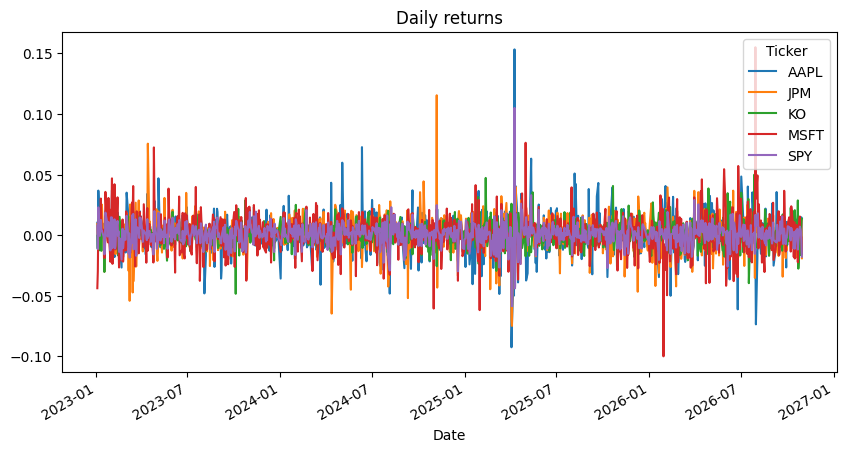

In [2]:
returns = prices.pct_change().dropna()
returns.plot(figsize=(10, 5), title="Daily returns")

In [ ]:
prices = yf.download(tickers, start="2023-01-01", end="2026-11-01", auto_adjust=True)["Close"]

# Portfolio Analysis: Risk, Return and Diversification
Comparing five stocks (Apple, Microsoft, JPMorgan, Coca-Cola) against the S&P 500 (SPY), January 2023 to October 2026.

<Axes: title={'center': 'Growth of $1 invested, Jan 2023 to Oct 2026'}, xlabel='Date'>

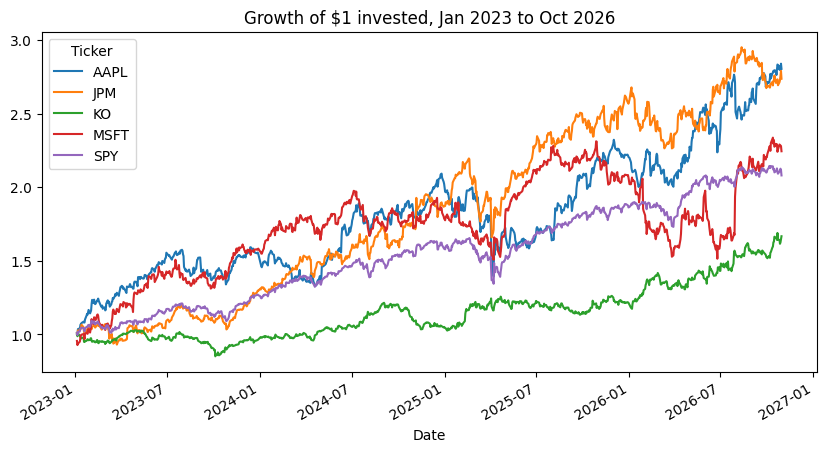

In [3]:
growth = (1 + returns).cumprod()
growth.plot(figsize=(10, 5), title="Growth of $1 invested, Jan 2023 to Oct 2026")

In [4]:
import numpy as np
import pandas as pd

summary = pd.DataFrame({
    "Annual return": returns.mean() * 252,
    "Annual volatility": returns.std() * np.sqrt(252),
})
summary["Return per unit of risk"] = summary["Annual return"] / summary["Annual volatility"]
summary.round(3).sort_values("Annual volatility")

,Annual return,Annual volatility,Return per unit of risk
Ticker,,,
SPY,0.203,0.149,1.368
KO,0.147,0.160,0.920
JPM,0.290,0.228,1.273
AAPL,0.303,0.256,1.185
MSFT,0.246,0.262,0.940


In [5]:
returns.corr().round(2)

Ticker,AAPL,JPM,KO,MSFT,SPY
Ticker,,,,,
AAPL,1.00,0.28,0.13,0.37,0.61
JPM,0.28,1.00,0.06,0.20,0.56
KO,0.13,0.06,1.00,-0.04,0.05
MSFT,0.37,0.20,-0.04,1.00,0.58
SPY,0.61,0.56,0.05,0.58,1.00
